# 08 · 历史数据量 H × 校准字符 k：探索性 SWLDA 分析

探索性分析，在看过测试结果之后进行，只使用 Train 验证。规则在运行前写定于 `docs/history_amount_exploratory_protocol.md` 和 `configs/history_amount_exploratory.json`。

历史池：每人 S1、S2 各 3 个 Train EDF，共 6 个文件、36 个字符，每个文件 6 个字符。按完整文件枚举 H=0–6，子集数依次为 1、6、15、20、15、6、1。当前池：S3 Train 前 12 个字符，取前 k∈{0,3,6,12} 个；最后 6 个字符为固定验证集。H=0、k=0 没有模型。

特征、质量规则和 SWLDA 设置与主实验相同（16 通道、256 维、A 规则）。共拟合 2,550 个模型，全部子集都保留。验证集共 7,560 个 flash，保护期排除 220 个，保留 7,340 个。主指标是 flash ROC-AUC：先对同一被试、同一 H,k 的全部子集取平均，再对被试取宏平均。

区间为按被试 bootstrap（10,000 次，种子 20261126）的百分位 95% 区间；差值先在被试内计算，再配对重采样。


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs/history_amount_exploratory.json').exists())
OUT = ROOT / 'outputs/history_amount_exploratory_v1'
if not (OUT / 'completion.json').exists():
    raise FileNotFoundError('请先完成 scripts/run_history_amount_exploratory.py；本 notebook 不启动拟合。')
macro = pd.read_csv(OUT / 'macro_summary.csv')
subject = pd.read_csv(OUT / 'subject_summary.csv')
subsets = pd.read_csv(OUT / 'subset_results.csv', dtype={'subset_id': str})
display(pd.Series(json.loads((OUT / 'completion.json').read_text())).to_frame('audit'))
if (OUT / 'independent_audit.json').exists():
    display(pd.Series(json.loads((OUT / 'independent_audit.json').read_text())).to_frame('independent checks'))


,audit
total_jobs,2560
fitted_models,2550
subjects,"[F_03, F_05, F_06, F_07, F_08, F_20, F_21, F_2..."
enumeration_complete,True
main_endpoint_checks,150
validation_flashes,7560
retained_validation_flashes,7340
bootstrap_replicates,10000
bootstrap_unit,subject
used_test,False


,independent checks
models_checked,2550
all_training_row_budgets_verified,True
all_auc_values_independently_verified,True
all_macro_and_paired_current_bootstrap_intervals_verified,True
no_test_inputs,True
frozen_source_hashes_unchanged,True
eegnet_manifest_only,True
session_contrasts_verified,12


## 历史数据量与校准量

先给放大的宏平均图，再给 10 名被试的 2×5 网格。所有面板纵轴为 0.4–1.0。配色：k=0（仅历史）为黑色方块；k=3、6、12 为由浅到深的紫色（圆、三角、菱形）。散点是各文件子集（加了轻微抖动），实线是子集均值。浅灰细虚线为仅当前参考，右侧标注对应的 k。宏平均画 k=3 与 k=12 的区间。k=12 仅当前 AUC ≥ 0.95 的被试，标题注明 “baseline near ceiling”。


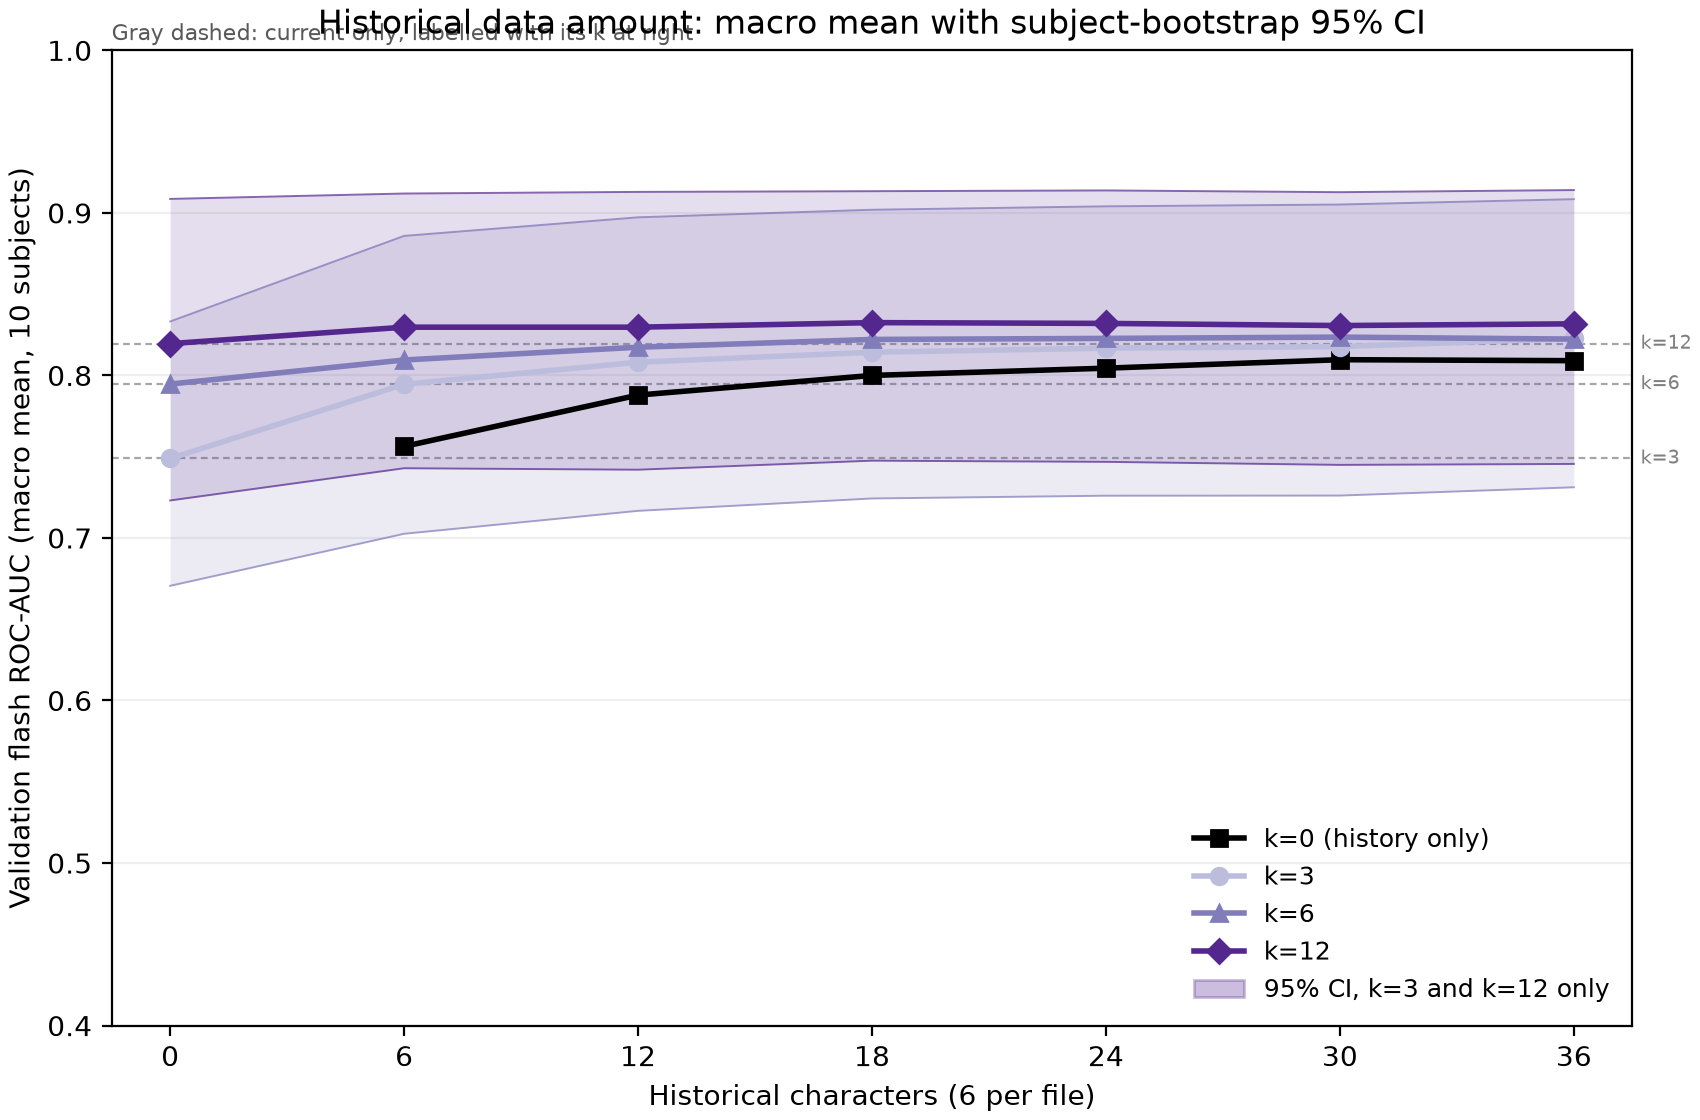

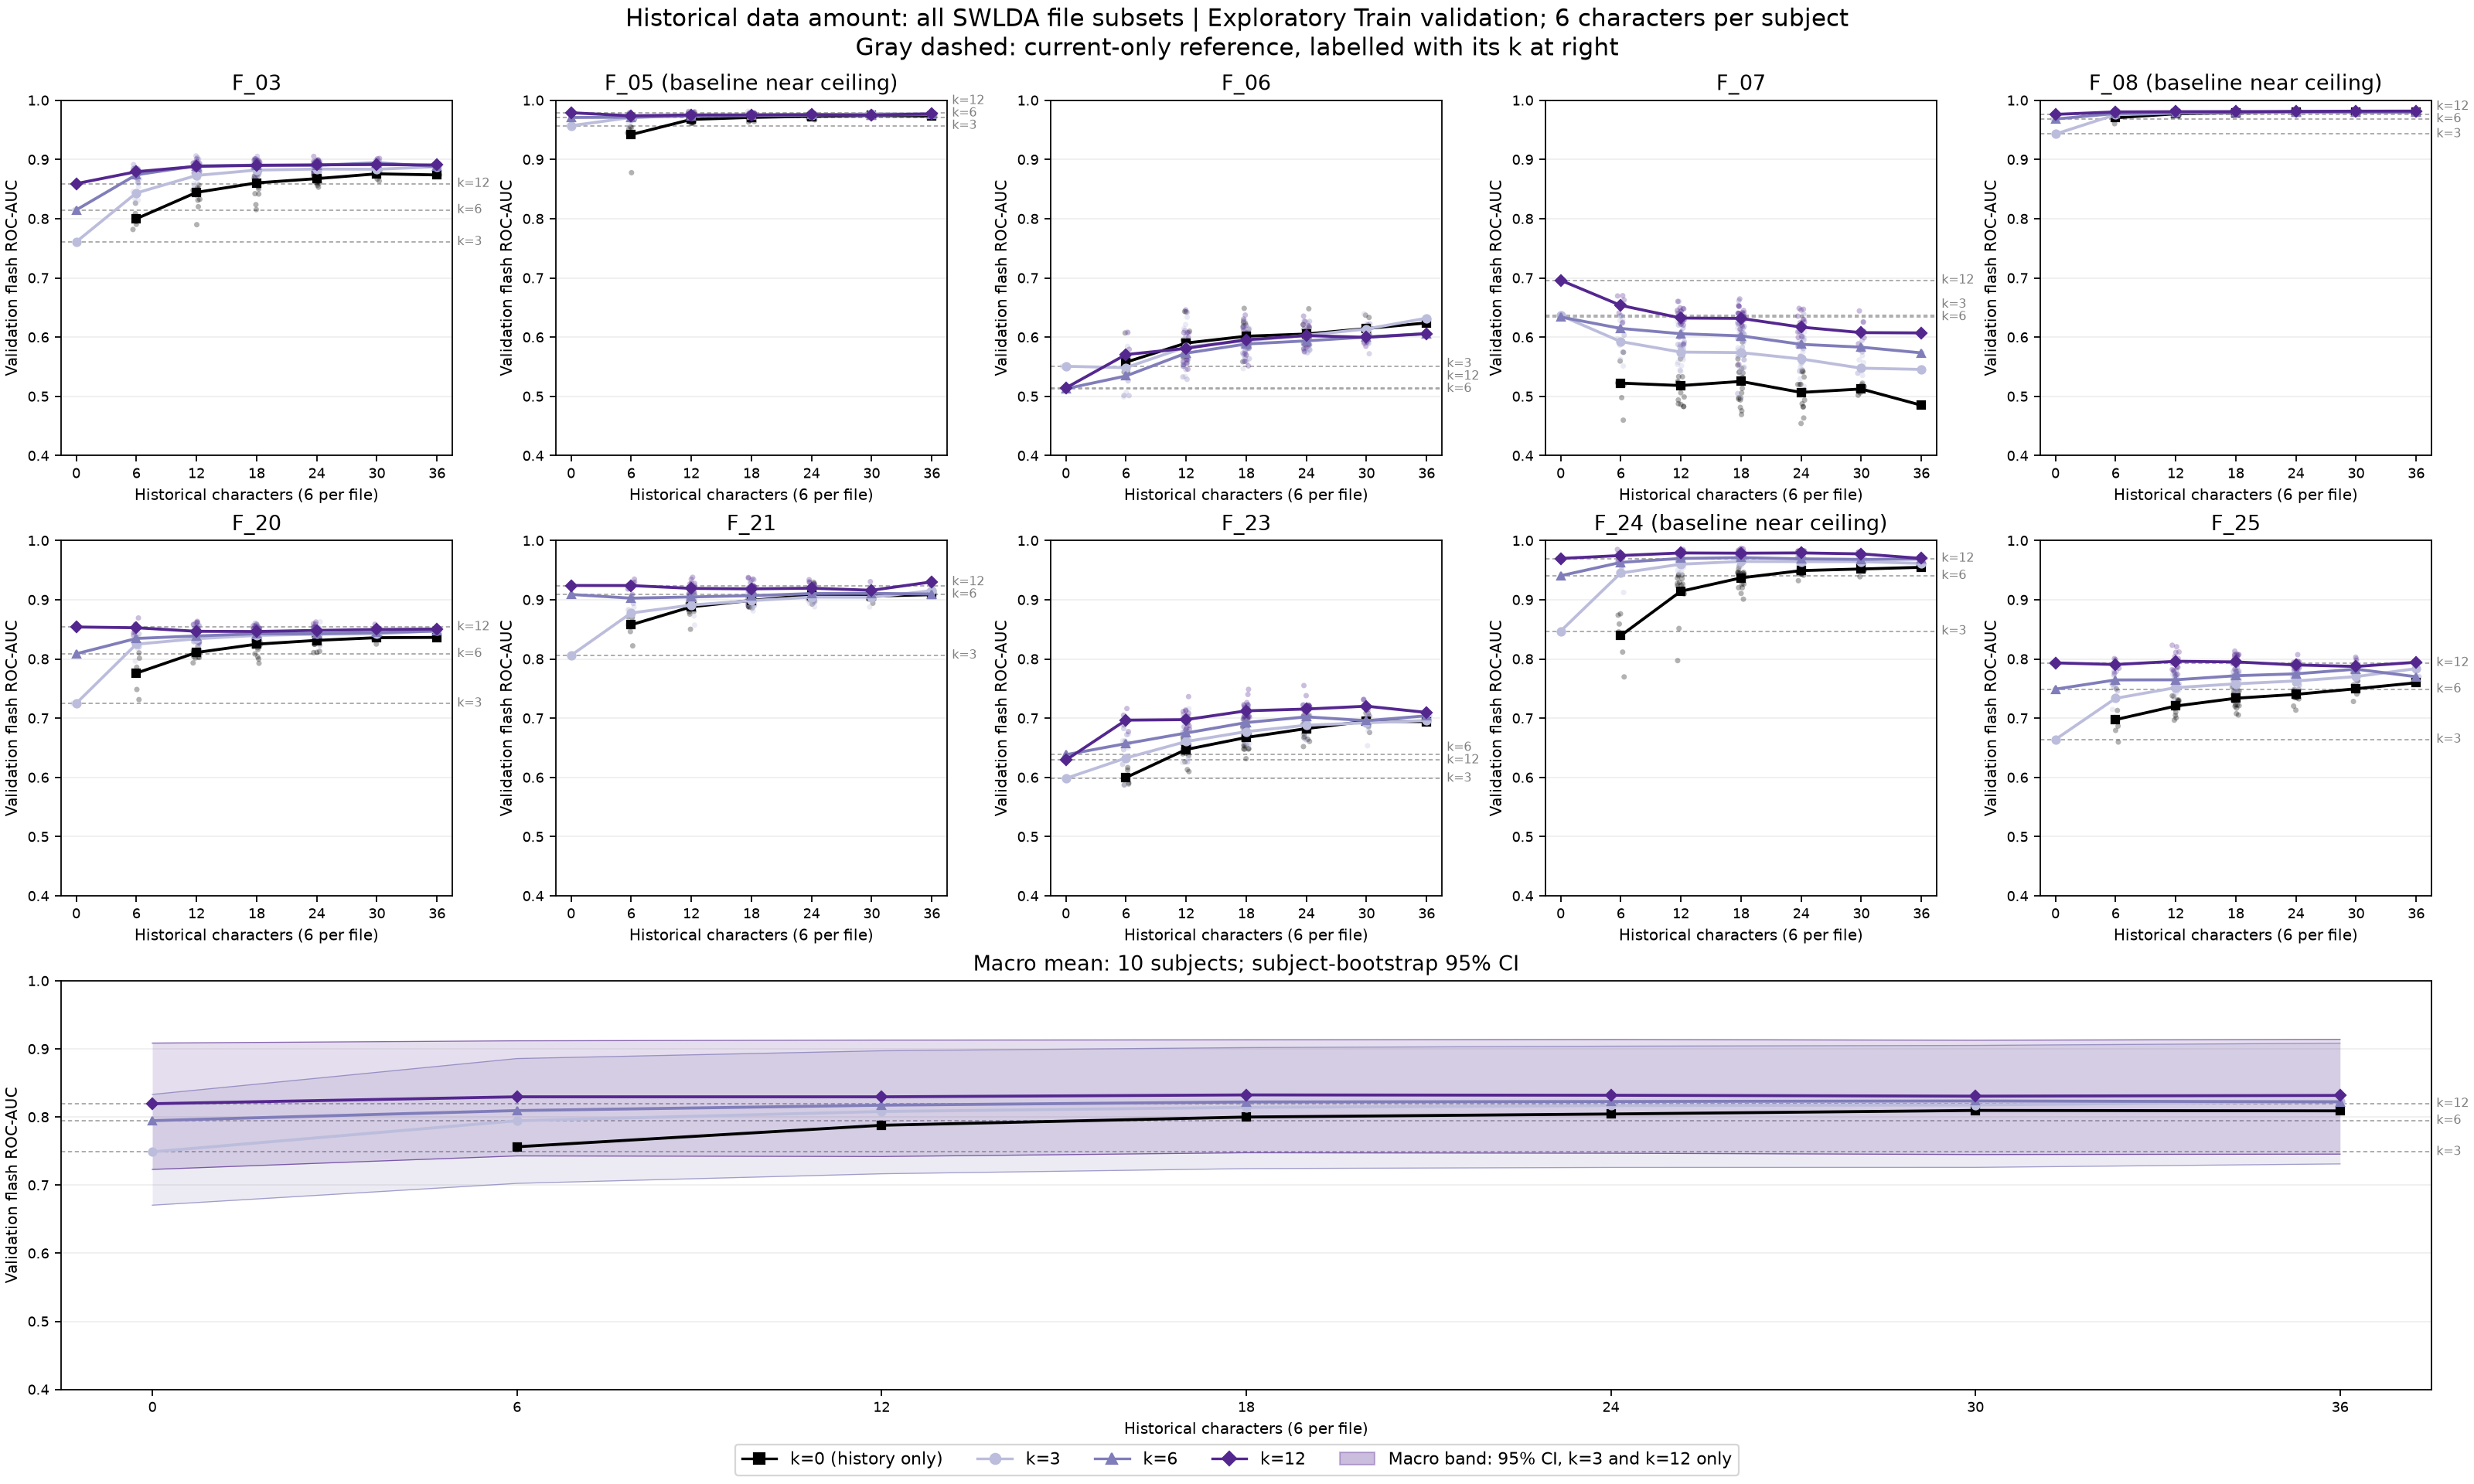

,H,k,history_characters,subsets_per_subject,mean_auc,ci_low,ci_high
0,0,0,0,1,NaN,NaN,NaN
1,0,3,0,1,0.748888,0.670548,0.833179
2,0,6,0,1,0.794682,0.701233,0.885908
3,0,12,0,1,0.819540,0.723067,0.908579
4,1,0,6,6,0.756307,0.666263,0.848213
5,1,3,6,6,0.794534,0.702564,0.885821
6,1,6,6,6,0.809479,0.715107,0.899747
7,1,12,6,6,0.829671,0.742886,0.911899
8,2,0,12,15,0.787886,0.693032,0.879978
9,2,3,12,15,0.808104,0.716675,0.897260


In [2]:
display(Image(filename=str(OUT / 'history_amount_macro.png')))
display(Image(filename=str(OUT / 'history_amount_small_multiples.png')))
display(macro[['H', 'k', 'history_characters', 'subsets_per_subject', 'mean_auc', 'ci_low', 'ci_high']])


## 相同 k 下相对仅当前的差异

每名被试计算 `mean_subset_auc(H,k) − current_only_auc(k)`，再对被试配对 bootstrap。k=0 没有仅当前模型，差值为空。


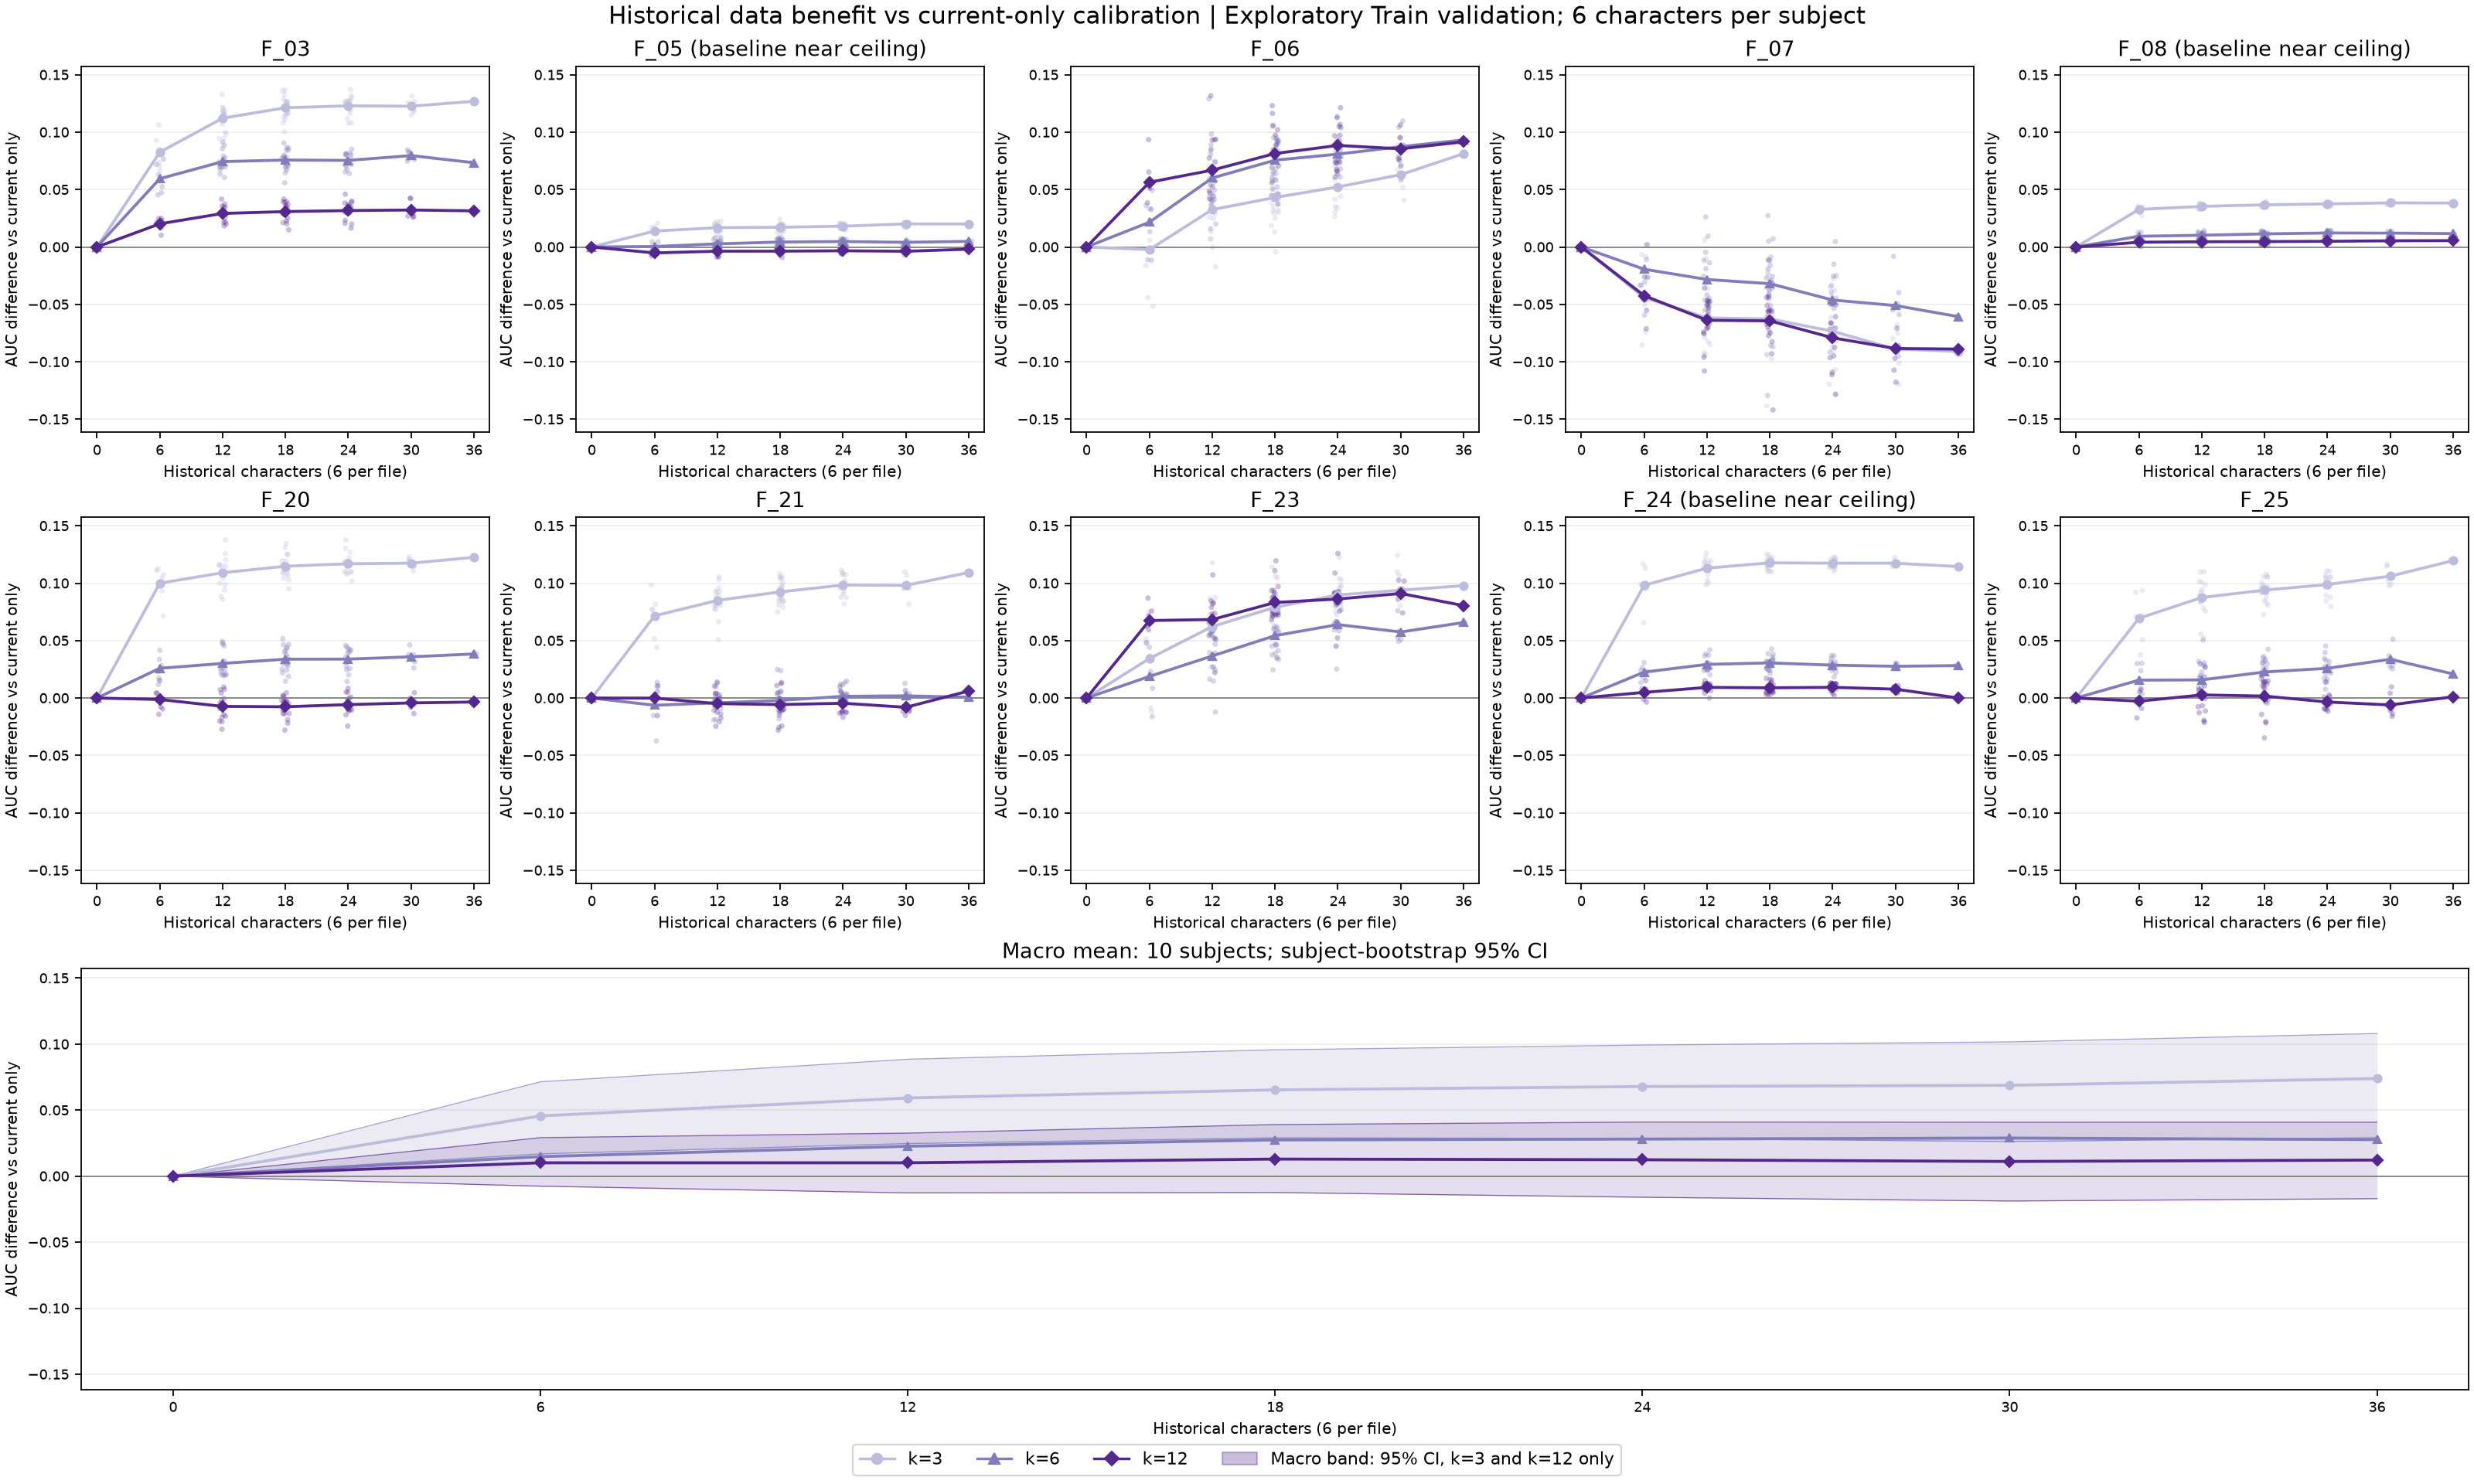

,H,k,history_characters,mean_auc,ci_low,ci_high,current_only_auc,delta_vs_current,delta_ci_low,delta_ci_high
0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,3,0,0.748888,0.670548,0.833179,0.748888,0.000000,0.000000,0.000000
2,0,6,0,0.794682,0.701233,0.885908,0.794682,0.000000,0.000000,0.000000
3,0,12,0,0.819540,0.723067,0.908579,0.819540,0.000000,0.000000,0.000000
4,1,0,6,0.756307,0.666263,0.848213,NaN,NaN,NaN,NaN
5,1,3,6,0.794534,0.702564,0.885821,0.748888,0.045646,0.016900,0.071466
6,1,6,6,0.809479,0.715107,0.899747,0.794682,0.014797,0.002751,0.027892
7,1,12,6,0.829671,0.742886,0.911899,0.819540,0.010131,-0.007585,0.029147
8,2,0,12,0.787886,0.693032,0.879978,NaN,NaN,NaN,NaN
9,2,3,12,0.808104,0.716675,0.897260,0.748888,0.059216,0.024670,0.088537


In [3]:
display(Image(filename=str(OUT / 'history_vs_current_small_multiples.png')))
display(pd.read_csv(OUT / 'paired_history_vs_current.csv'))


## Session 来源：相同文件数下，仅 S2 减仅 S1

每个 Session 有 3 个文件，所以纯 Session 对照定义在 H=1、2、3。每名被试先分别平均全部纯 S1、纯 S2 子集，再求差；正值表示 S2 更高。S2 在时间上更接近 S3，二者的差异同时包含时间顺序和记录状态的影响。


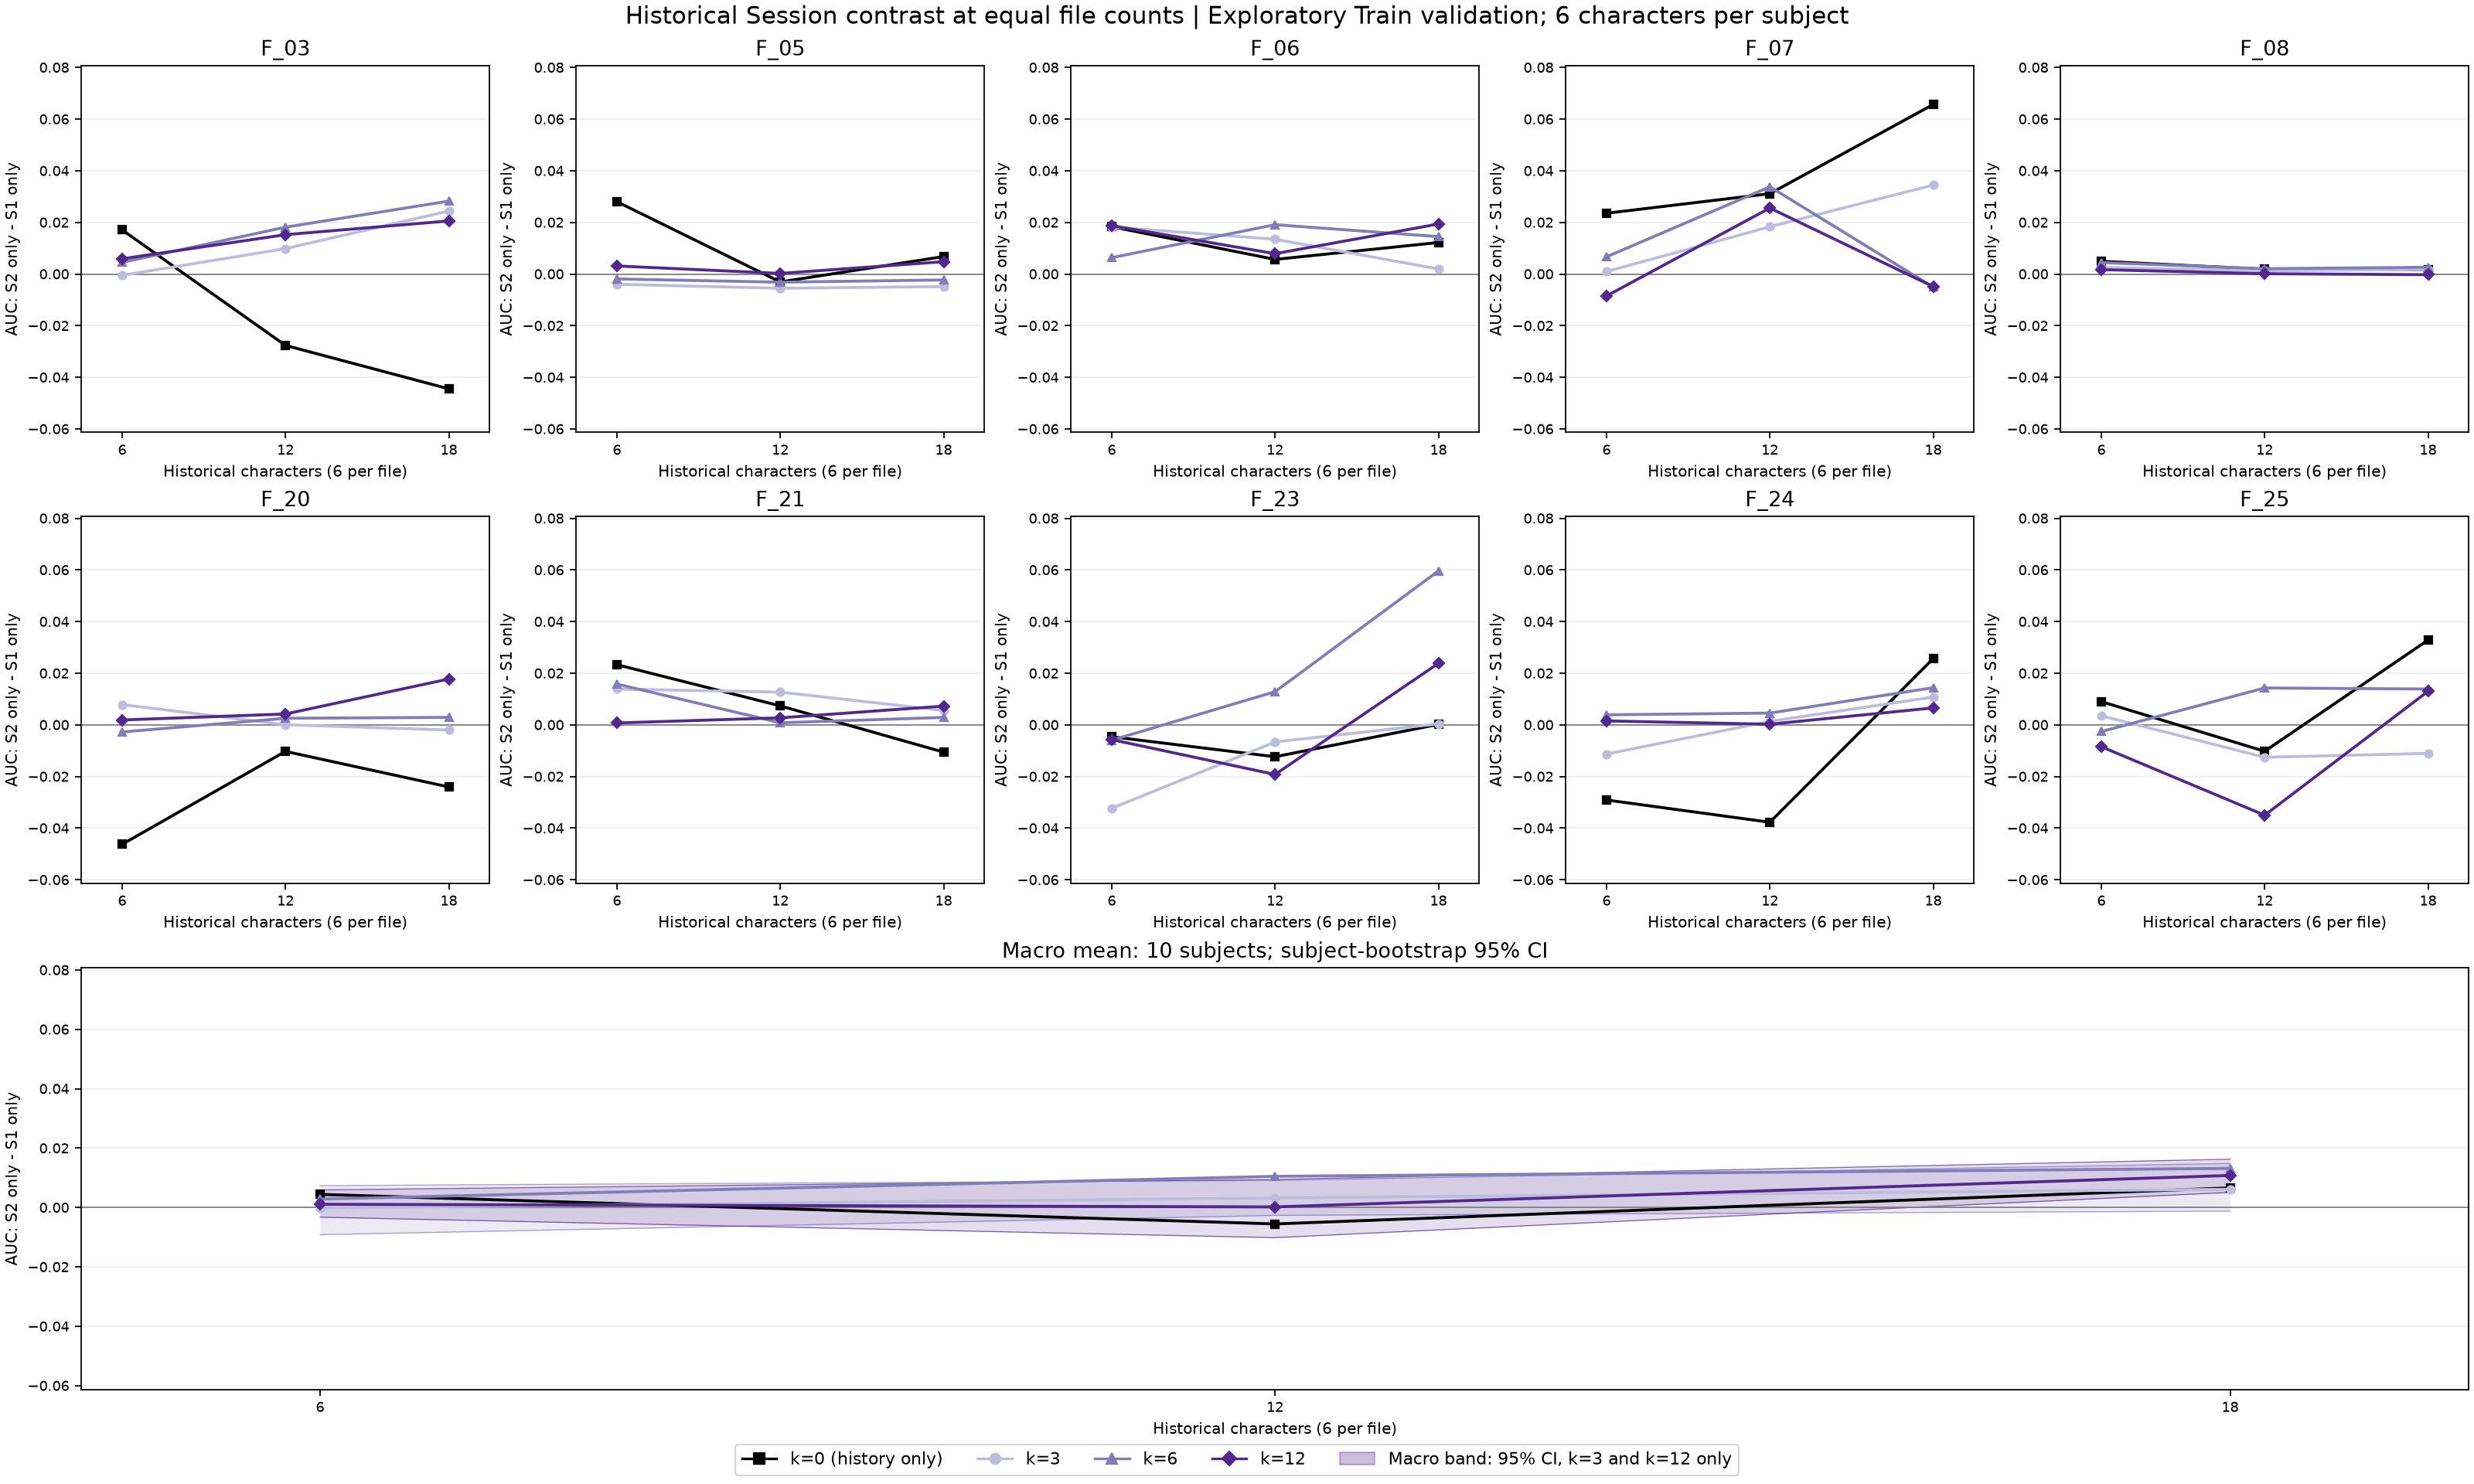

,H,k,history_characters,subjects,s1_mean_auc,s2_mean_auc,delta_s2_minus_s1,ci_low,ci_high
0,1,0,6,10,0.754098,0.758515,0.004417,-0.011099,0.017579
1,1,3,6,10,0.794596,0.794472,-0.000124,-0.009154,0.007358
2,1,6,6,10,0.808062,0.810897,0.002835,-0.000657,0.006705
3,1,12,6,10,0.829127,0.830215,0.001088,-0.003265,0.005915
4,2,0,12,10,0.787121,0.781584,-0.005537,-0.016515,0.005783
5,2,3,12,10,0.806943,0.810164,0.003221,-0.002648,0.009126
6,2,6,12,10,0.811540,0.822033,0.010493,0.004158,0.017430
7,2,12,12,10,0.830588,0.830781,0.000193,-0.010150,0.009455
8,3,0,18,10,0.789758,0.796351,0.006594,-0.010770,0.024601
9,3,3,18,10,0.804796,0.810932,0.006136,-0.001220,0.014838


In [4]:
display(Image(filename=str(OUT / 'session_contrast_small_multiples.png')))
display(pd.read_csv(OUT / 'session_macro_contrasts.csv'))


## 附录：逐被试 AUC 与字符准确率


### F_03

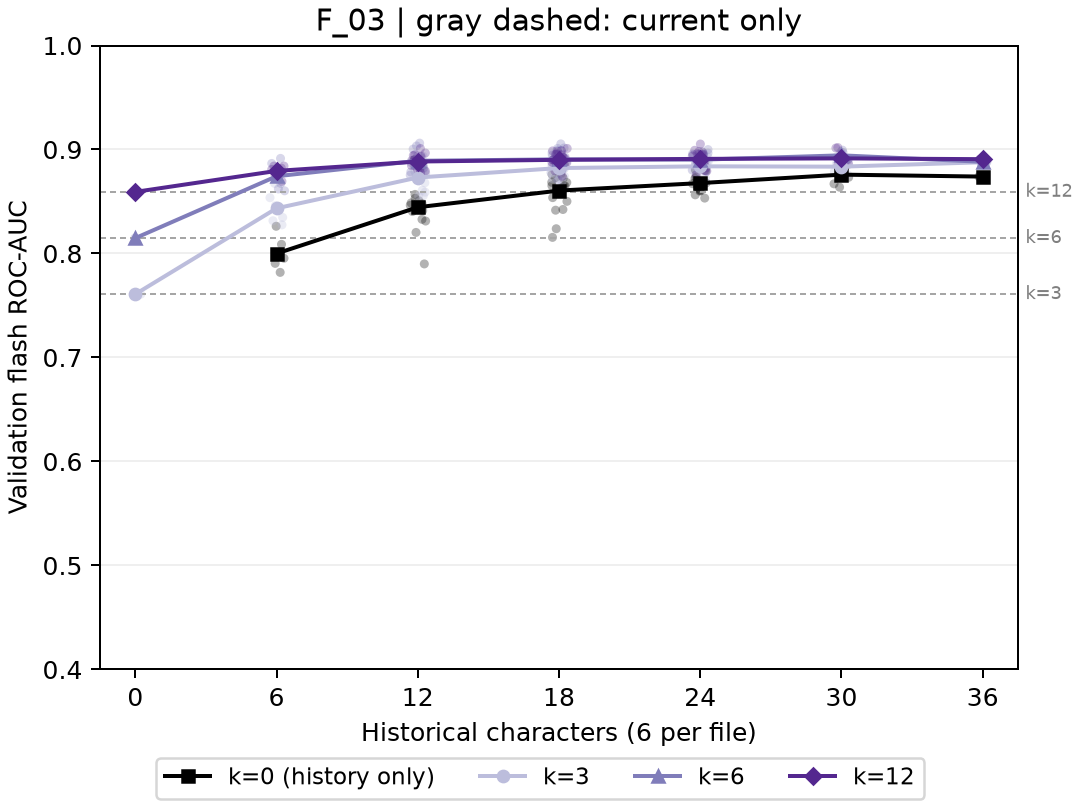

k,0,3,6,12
history_characters,,,,
0,NaN,0.760895,0.814796,0.859244
6,0.799961,0.843448,0.874259,0.879411
12,0.844482,0.873063,0.889149,0.888439
18,0.860486,0.882152,0.890515,0.890067
24,0.867696,0.883823,0.890211,0.890966
30,0.875825,0.883504,0.894381,0.891454
36,0.873953,0.887755,0.888170,0.890704


### F_05

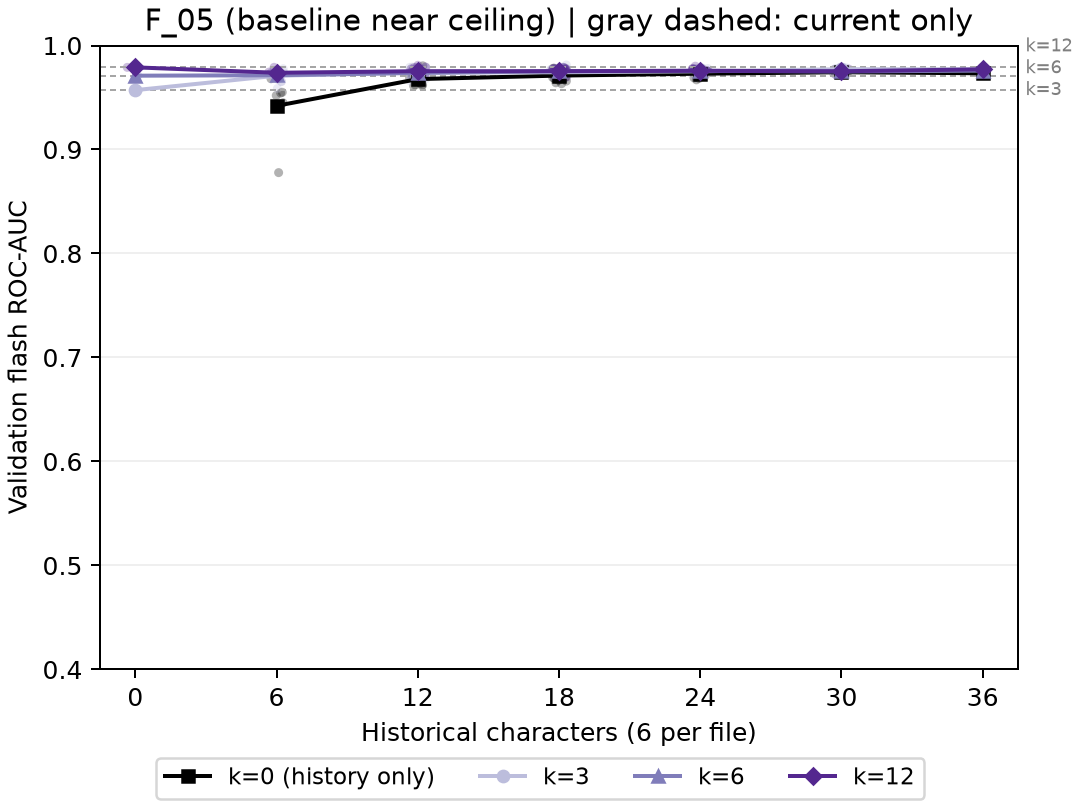

k,0,3,6,12
history_characters,,,,
0,NaN,0.957074,0.970971,0.978977
6,0.941992,0.970952,0.971395,0.973783
12,0.967685,0.973868,0.973693,0.975297
18,0.971068,0.974247,0.975266,0.975325
24,0.972888,0.975202,0.975717,0.975676
30,0.974291,0.977175,0.975021,0.975223
36,0.973290,0.977069,0.975853,0.977069


### F_06

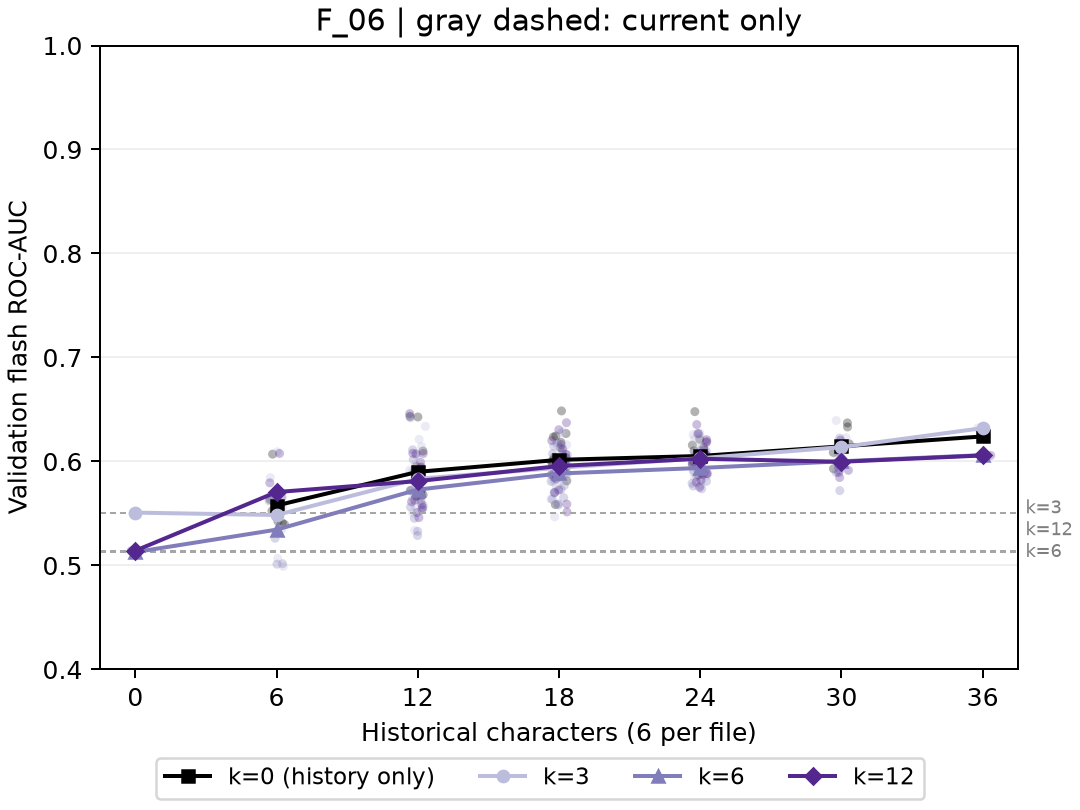

k,0,3,6,12
history_characters,,,,
0,NaN,0.550838,0.512887,0.514234
6,0.557684,0.548528,0.534462,0.570611
12,0.590054,0.583372,0.572969,0.581135
18,0.601602,0.593959,0.588467,0.595650
24,0.605313,0.603126,0.593772,0.602667
30,0.614551,0.613834,0.600204,0.599731
36,0.624102,0.632089,0.606146,0.605810


### F_07

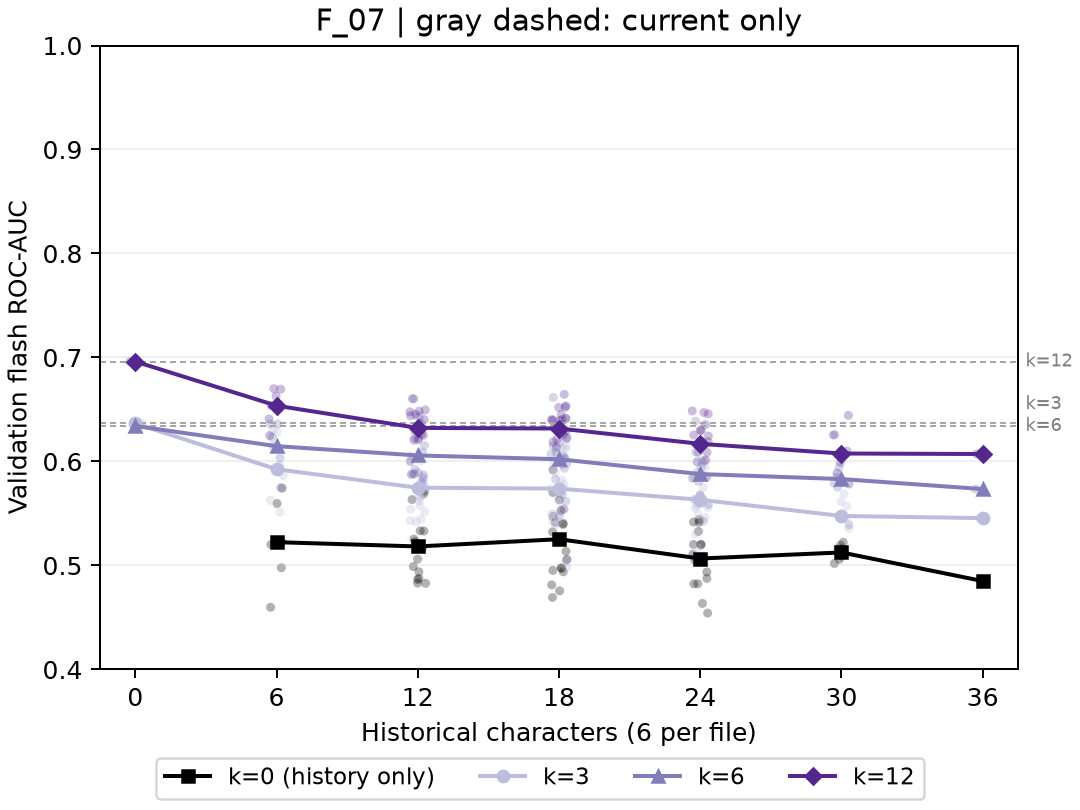

k,0,3,6,12
history_characters,,,,
0,NaN,0.636615,0.634128,0.696113
6,0.522439,0.592554,0.614744,0.653673
12,0.518304,0.574796,0.605803,0.632285
18,0.525286,0.573923,0.602182,0.631722
24,0.506704,0.563210,0.587920,0.616990
30,0.512541,0.547646,0.583115,0.607677
36,0.485037,0.545545,0.573470,0.607194


### F_08

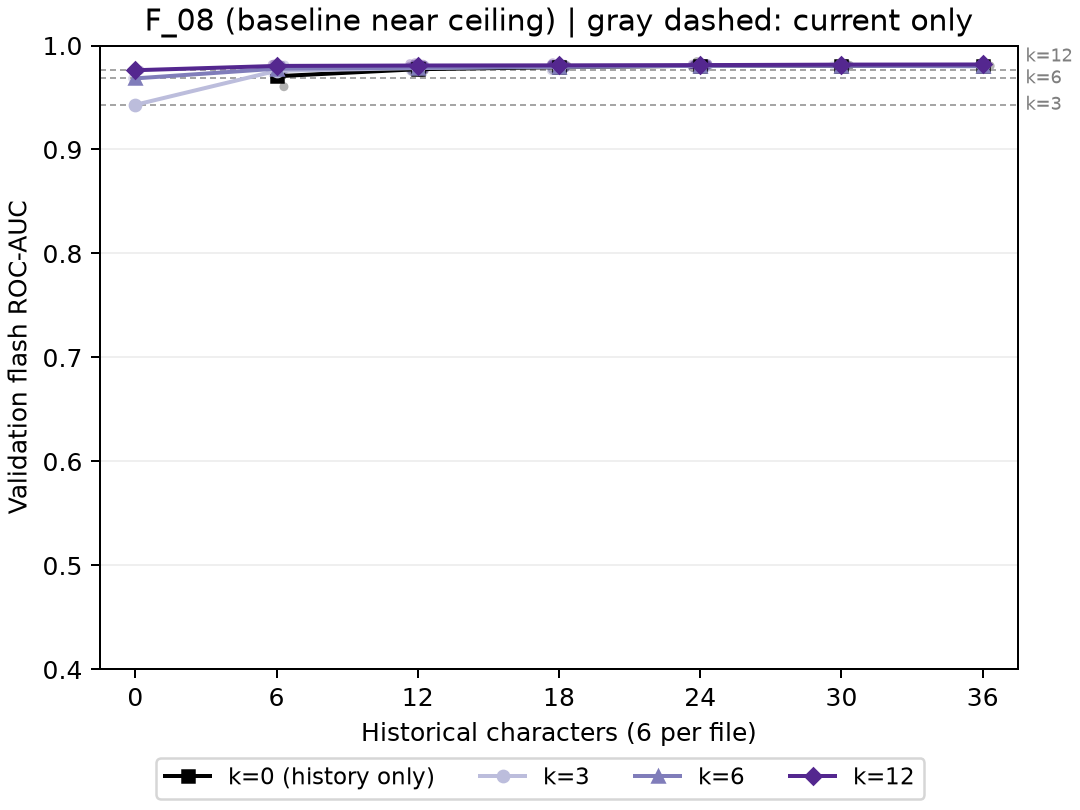

k,0,3,6,12
history_characters,,,,
0,NaN,0.942941,0.968370,0.976216
6,0.970440,0.975662,0.977713,0.980366
12,0.977203,0.978321,0.978577,0.980759
18,0.979185,0.979645,0.979772,0.980907
24,0.980510,0.980470,0.980571,0.981147
30,0.980643,0.981346,0.980464,0.981608
36,0.980319,0.981188,0.980035,0.981756


### F_20

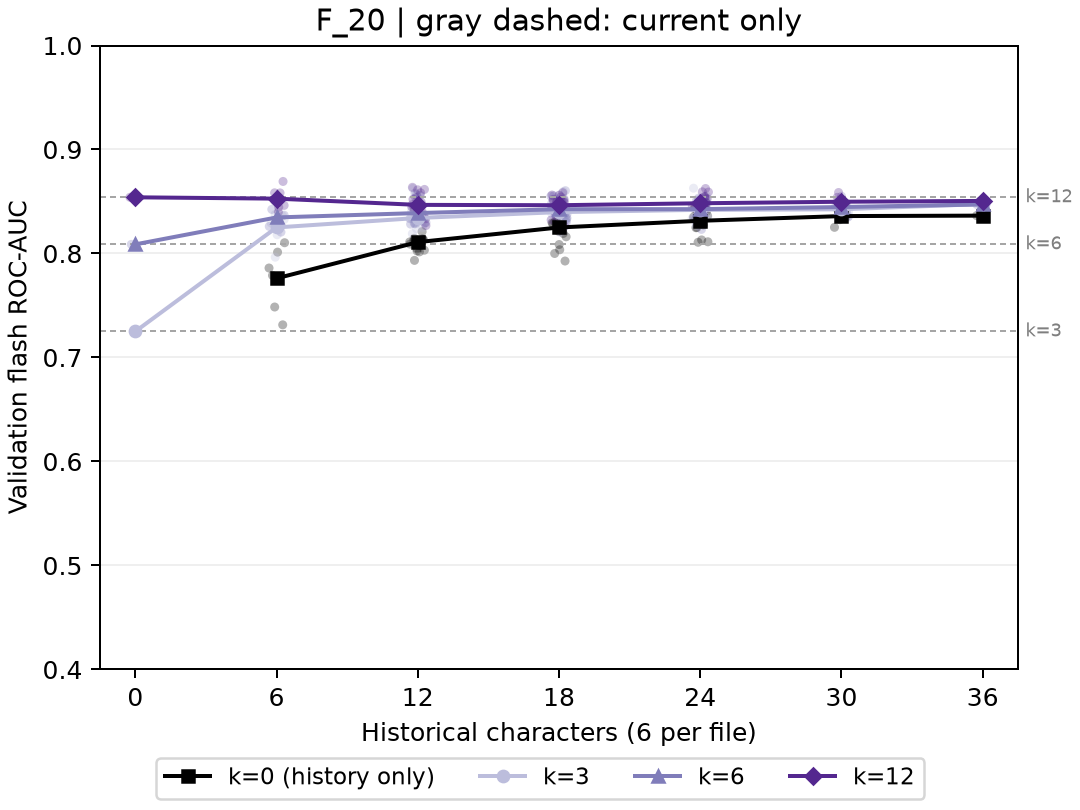

k,0,3,6,12
history_characters,,,,
0,NaN,0.725030,0.808769,0.854033
6,0.776099,0.825041,0.834664,0.852745
12,0.810943,0.834170,0.838892,0.846753
18,0.825028,0.839805,0.842602,0.846414
24,0.831452,0.841968,0.842652,0.848298
30,0.835980,0.842492,0.844681,0.849774
36,0.836413,0.847561,0.847131,0.850554


### F_21

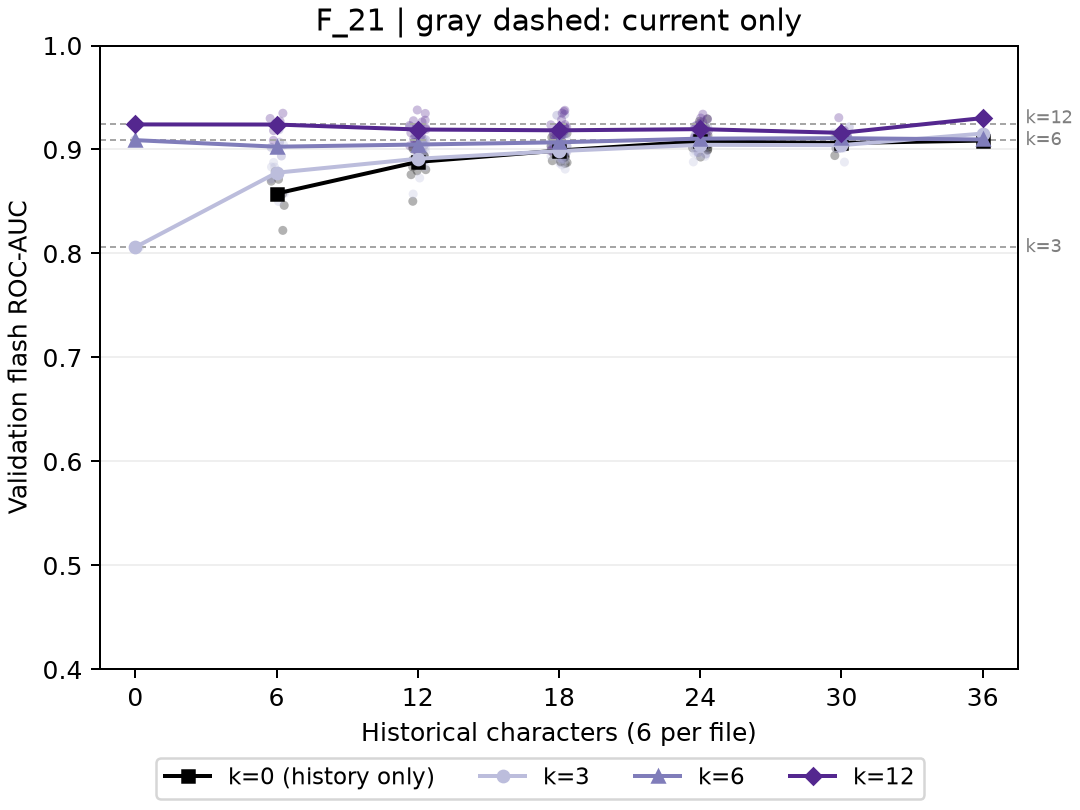

k,0,3,6,12
history_characters,,,,
0,NaN,0.806080,0.908986,0.924111
6,0.857659,0.877665,0.902684,0.924010
12,0.888099,0.891111,0.904781,0.919218
18,0.899009,0.898522,0.906922,0.918438
24,0.907790,0.904496,0.910463,0.919573
30,0.906175,0.904174,0.910874,0.916032
36,0.908589,0.915339,0.909648,0.930218


### F_23

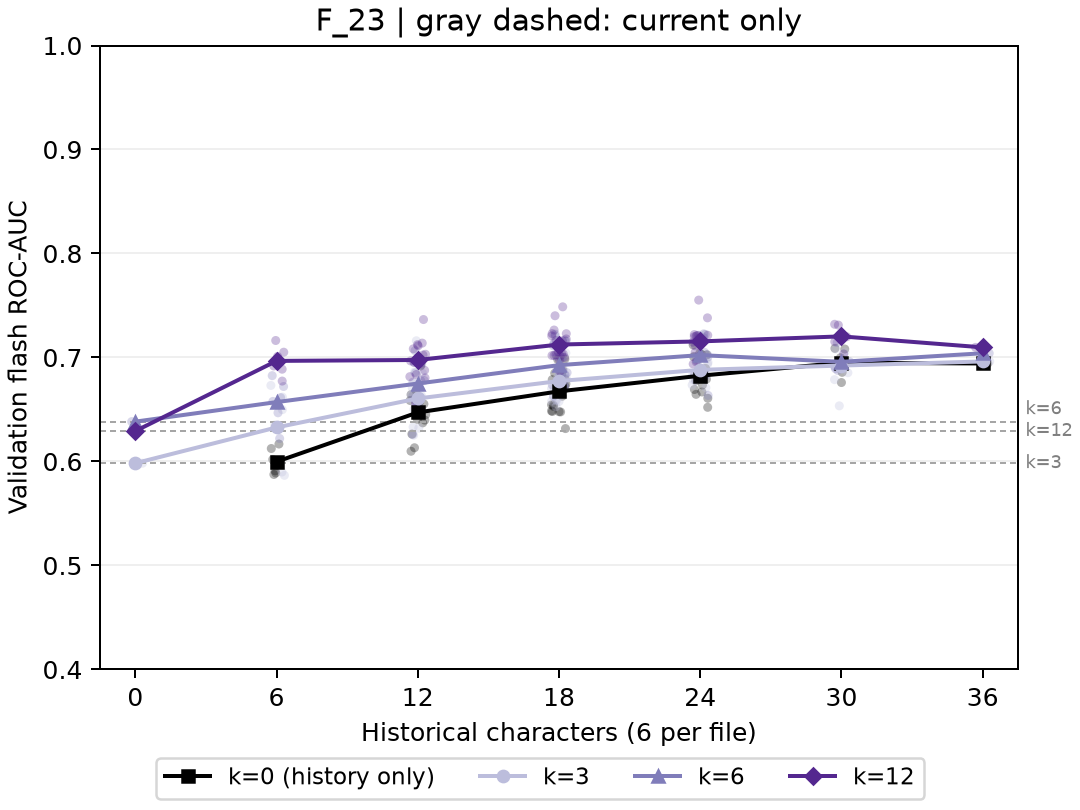

k,0,3,6,12
history_characters,,,,
0,NaN,0.598359,0.638326,0.629252
6,0.599786,0.632762,0.657122,0.696731
12,0.647161,0.660598,0.674959,0.697607
18,0.667441,0.677387,0.692643,0.712453
24,0.682472,0.688119,0.702286,0.715478
30,0.694944,0.692259,0.695832,0.720303
36,0.694251,0.696198,0.704082,0.709754


### F_24

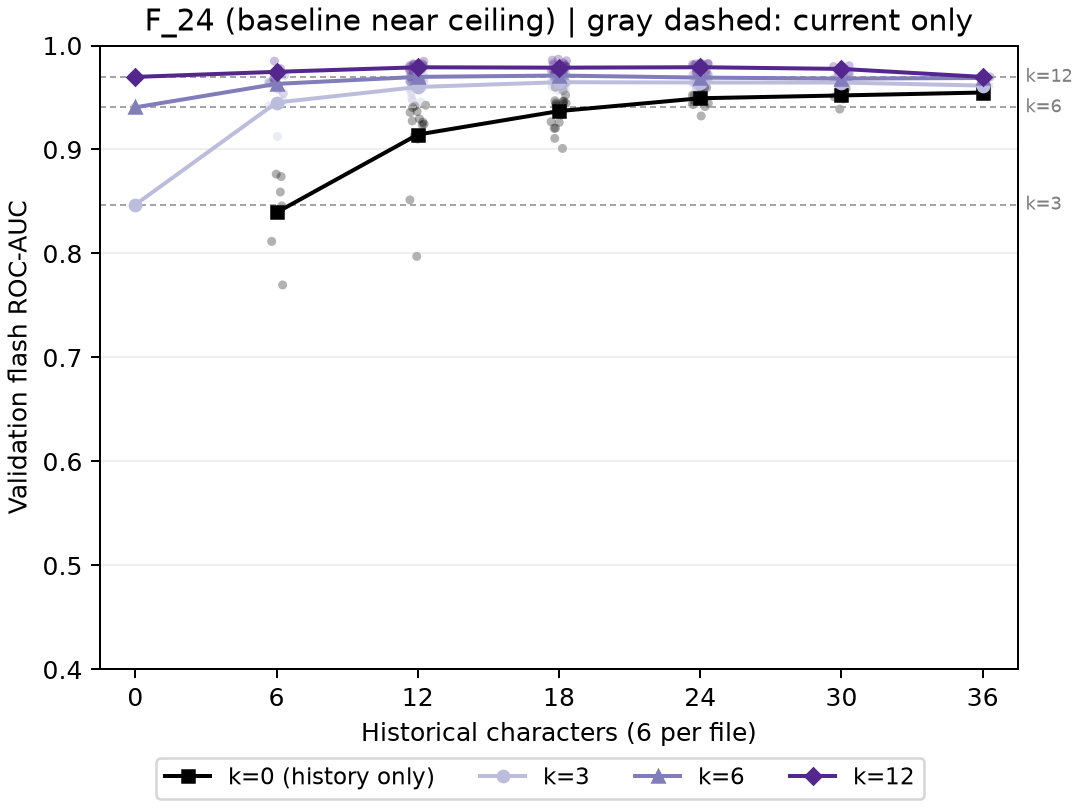

k,0,3,6,12
history_characters,,,,
0,NaN,0.846955,0.940521,0.969788
6,0.839424,0.945150,0.963102,0.974700
12,0.914364,0.960106,0.969821,0.979065
18,0.936931,0.964700,0.971113,0.978688
24,0.949281,0.964404,0.969125,0.979110
30,0.951979,0.964378,0.968178,0.977499
36,0.954796,0.961450,0.968748,0.969807


### F_25

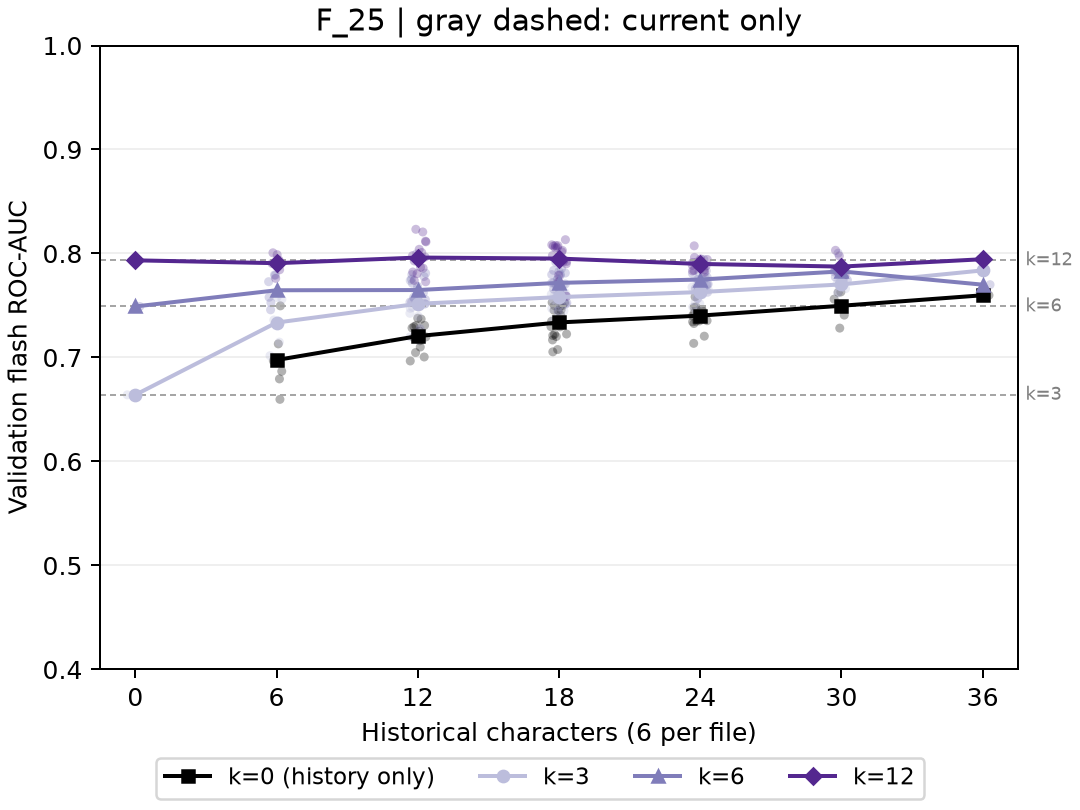

k,0,3,6,12
history_characters,,,,
0,NaN,0.664092,0.749065,0.793431
6,0.697582,0.733575,0.764648,0.790678
12,0.720560,0.751638,0.764855,0.796117
18,0.733711,0.758078,0.771747,0.795119
24,0.740281,0.762926,0.774951,0.789963
30,0.749747,0.770260,0.782798,0.787402
36,0.759838,0.783742,0.770032,0.794497


,H,k,mean_character_accuracy
0,0,0,NaN
1,0,3,0.650000
2,0,6,0.700000
3,0,12,0.766667
4,1,0,0.669444
5,1,3,0.719444
6,1,6,0.744444
7,1,12,0.786111
8,2,0,0.724444
9,2,3,0.750000


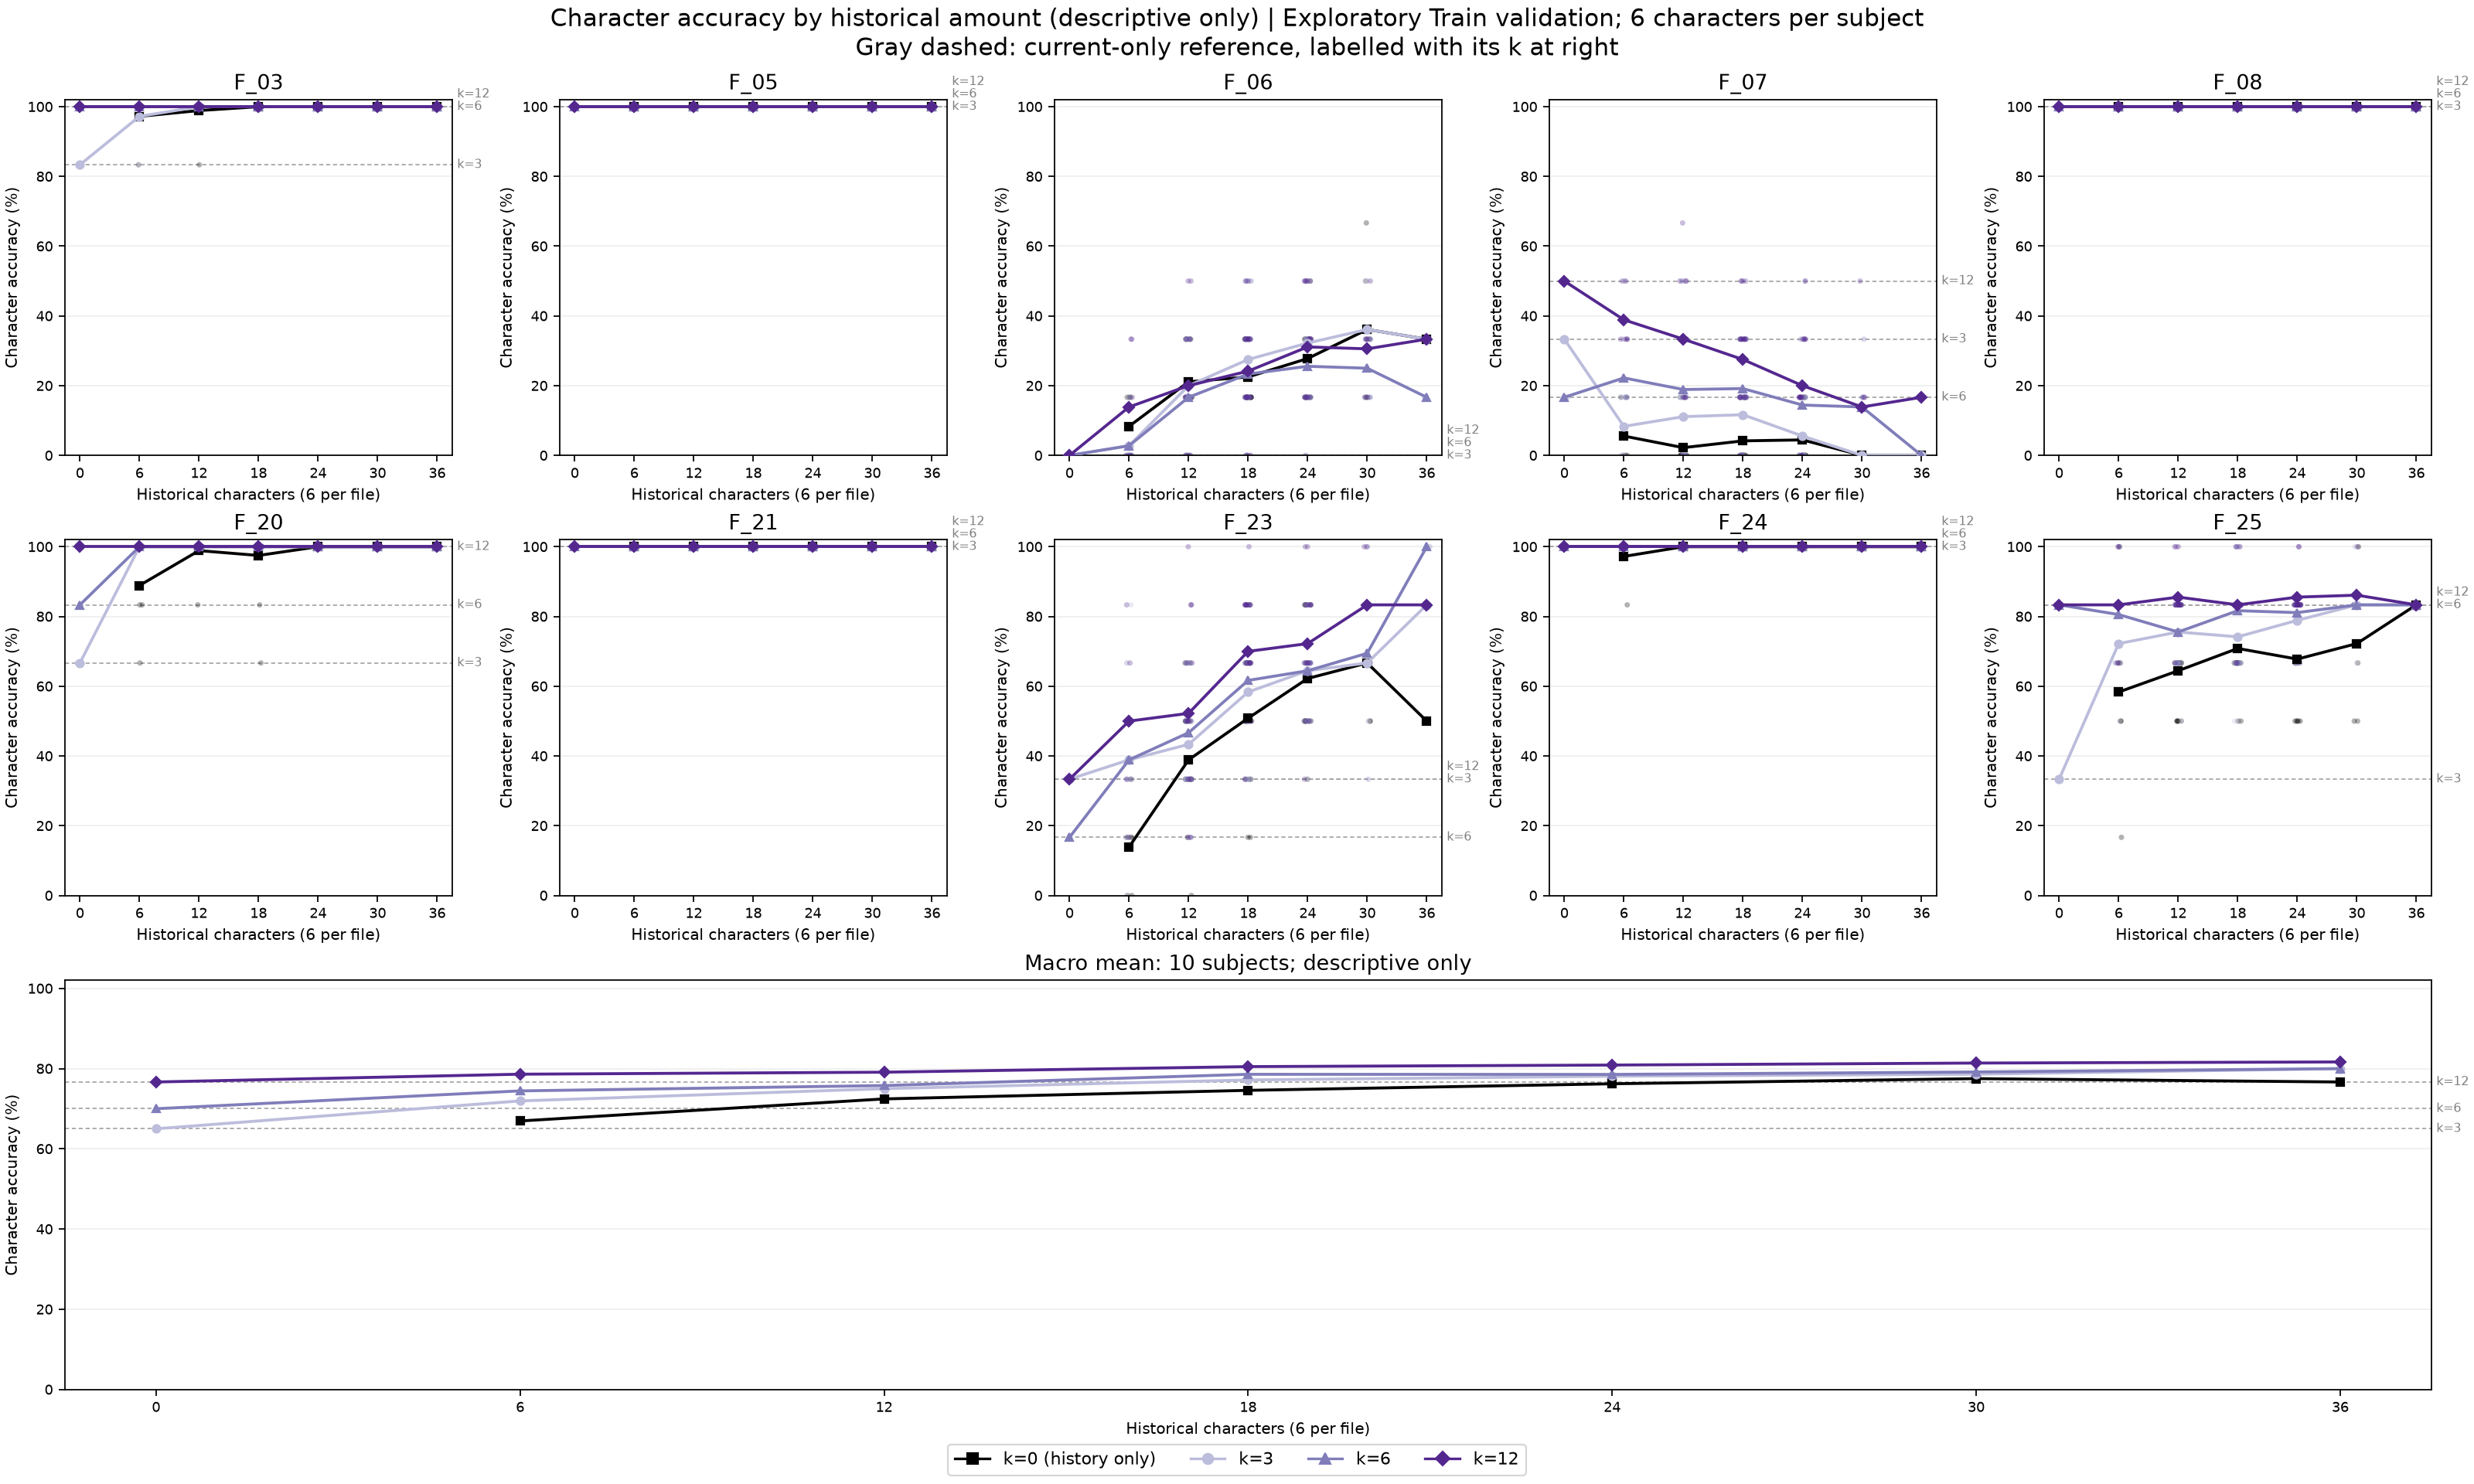

In [5]:
for sid in sorted(subject.subject_id.unique()):
    display(Markdown('### ' + sid))
    display(Image(filename=str(OUT / 'subjects' / (sid + '.png'))))
    g = subject[subject.subject_id.eq(sid)]
    display(g.pivot(index='history_characters', columns='k', values='mean_auc'))
display(macro[['H', 'k', 'mean_character_accuracy']])
display(Image(filename=str(OUT / 'character_accuracy_small_multiples.png')))


## EEGNet 子集计划

`eegnet_subset_plan.csv` 为每个 H 固定种子 0–4 的子集，在不同 k 之间复用，并记录 S1/S2 文件数。H=0 和 H=6 只有一种文件组合。EEGNet 训练按 `docs/eegnet_protocol.md` 进行，epoch 数在训练前固定。


## 复现与输出

运行：`python scripts/run_history_amount_exploratory.py`，可从已完成的模型续跑。独立审计：`python scripts/audit_history_amount_exploratory.py`。重画图：`python scripts/plot_history_amount.py`；重建报告：`python scripts/build_history_amount_notebook.py`。

- `history_file_pool.csv`、`enumeration_manifest.csv`：历史文件、组合及 S1/S2 构成。
- `character_roles.csv`、`validation_flash_manifest.csv`：字符角色与验证 flash。
- `subset_results.csv`、`jobs/`：全部子集的指标、模型、逐字符预测和训练特征行。
- `subject_summary.csv`、`macro_summary.csv`：逐被试与宏平均结果。
- `paired_history_vs_current.csv`、`session_subject_contrasts.csv`、`session_macro_contrasts.csv`：对照与区间。
- `main_endpoint_checks.csv`：与主实验对应端点的一致性检查。
